# Khôi phục tín hiệu trên đồ thị bằng điều chuẩn Laplacian
## I–II. Bài toán và yêu cầu
Cho đồ thị vô hướng có trọng số $G=(V,E,W)$ và tín hiệu quan sát $y=x^*+\epsilon+o$. Tín hiệu sạch $x^*$ không được công bố. Mục tiêu là ước lượng 32 giá trị theo đúng thứ tự đỉnh để giảm RMSE ẩn. Nhiễu cộng và ngoại lai là giả thiết phương pháp, không phải cơ chế sinh dữ liệu đã xác minh. README yêu cầu notebook và CSV bốn cột; code được khuyến khích nhưng không bắt buộc. Bản này theo README, không phải mẫu notebook gốc (không có trong hai file hiện hành).
## III. Thông tin nhóm
MSSV 2480859 chưa có trong dữ liệu. Dùng 20260001 cố định làm minh họa, không lựa chọn bộ đề dễ hơn. Không nộp CSV minh họa thay bài chính thức.

In [1]:
import os
os.environ['OPENBLAS_NUM_THREADS']='1'
import json, csv, numpy as np, networkx as nx, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from scipy.optimize import minimize
from scipy.linalg import solve
db=json.loads(Path('public_cases.json').read_text())
DEMO=True
NHOM_MSSV=['20260001'] if DEMO else ['2480859'] # bổ sung thành viên thật
sid=NHOM_MSSV[0]
print(db['version'], len(db['cases']), 'cases; 2480859 exists:', '2480859' in db['cases'])
assert sid in db['cases'], 'Liên hệ giảng viên để nhận bộ đề chính thức'


CST-GRAPH-V1 100 cases; 2480859 exists: False


## IV–V. Đọc và khảo sát đồ thị
Giữ nguyên cạnh, trọng số và thứ tự đỉnh được cung cấp. Tọa độ dùng để trực quan hóa, không tự tạo thêm cạnh.

In [2]:
def load_case(sid):
    z=db['cases'][sid]; nodes=z['nodes']; y=np.array(z['y'],float)
    G=nx.Graph(); G.add_nodes_from(nodes); G.add_weighted_edges_from(z['edges'])
    W=nx.to_numpy_array(G,nodelist=nodes); L=np.diag(W.sum(1))-W
    assert nodes==list(range(32)) and nx.is_connected(G) and np.isfinite(y).all() and (W>=0).all()
    return nodes,y,G,W,L,dict(zip(nodes,z['positions']))
nodes,y,G,W,L,pos=load_case(sid)
print('Nodes, edges, min, max, energy:',len(nodes),G.number_of_edges(),y.min(),y.max(),y@L@y)
print('All provided cases validated:',sum(bool(load_case(k)) for k in db['cases']))
def graphplot(y,x):
    fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained')
    lo=min(y.min(),x.min()); hi=max(y.max(),x.max())
    for ax,v,t in zip(axes,[y,x],['Observed','Recovered']):
        nx.draw_networkx_edges(G,pos,ax=ax,alpha=.25)
        a=nx.draw_networkx_nodes(G,pos,node_color=v,nodelist=nodes,ax=ax,cmap='viridis',vmin=lo,vmax=hi)
        nx.draw_networkx_labels(G,pos,ax=ax,font_size=8); ax.set_title(t); ax.axis('off')
    fig.colorbar(a,ax=axes); plt.show()


Nodes, edges, min, max, energy: 32 80 16.57956741 21.66533968 73.6499778243255
All provided cases validated: 100


## VI. Mô hình toán học và phương pháp giải (bắt buộc)
### 6.1 Giả thiết và tính không xác định
Chỉ biết $y$ không đủ để phân tách tín hiệu sạch và nhiễu. Giả thiết các đỉnh liên kết mạnh có tín hiệu sạch tương đối gần nhau, đa số phép đo hữu ích, và một số phép đo có thể chứa sai lệch lớn. Đây là giả thiết cần kiểm tra, không phải kết luận về dữ liệu. Đặt $D_{ii}=\sum_j w_{ij}$, $L=D-W$. Khi đó $x^TLx=\sum_{\{i,j\}\in E}w_{ij}(x_i-x_j)^2\ge0$. Điều chuẩn làm giảm biến thiên trên cạnh nhưng có thể xóa ranh giới thật.
### 6.2 Mô hình đối chứng L2
Theo nguyên lý Tikhonov trên Laplacian [1], với mặt nạ quan sát $m_i\in\{0,1\}$, $M=\operatorname{diag}(m)$:
$$F_2(x)=\tfrac12(x-y)^TM(x-y)+\tfrac\lambda2 x^TLx.$$
Điều kiện tối ưu $(M+\lambda L)x=My$. Khi đủ quan sát, $M=I$, nghiệm duy nhất vì Hessian xác định dương. Khi che đỉnh, với đồ thị liên thông, $\lambda>0$ và ít nhất một quan sát, tính xác định dương vẫn đúng: nếu $v^T(M+\lambda L)v=0$ thì $v$ hằng trên đồ thị và bằng 0 tại đỉnh quan sát, do đó $v=0$. Giải hệ trực tiếp phù hợp với 32 đỉnh; không tuyên bố cài đặt Gauss–Seidel của [1]. Trong miền phổ, với đủ quan sát, đáp ứng lọc là $1/(1+\lambda\mu)$ với $\mu$ là trị riêng Laplacian.
### 6.3 Mô hình Huber–Laplacian
Vận dụng mất mát Huber [2] và IRLS [3]:
$$F_H(x)=\sum_i m_i\rho_\delta(x_i-y_i)+\tfrac\lambda2 x^TLx,$$
$$\rho_\delta(r)=\begin{cases}r^2/2&|r|\le\delta\\\delta|r|-\delta^2/2&|r|>\delta.\end{cases}$$
Đạo hàm $\psi_\delta(r)=\operatorname{clip}(r,-\delta,\delta)$ giới hạn ảnh hưởng của phần dư lớn. Hàm mục tiêu lồi, có nghiệm (coercive do liên thông và ít nhất một quan sát), nhưng không khẳng định luôn duy nhất. IRLS đặt $a_i=m_i\min(1,\delta/|r_i|)$, với tỷ số tại 0 được quy ước sao cho trọng số bằng $m_i$. Giải $(\operatorname{diag}(a)+\lambda L)x^{k+1}=a\odot y$. Đây là cập nhật majorization-minimization: hàm $\rho_\delta(\sqrt u)$ lõm theo $u\ge0$, tiếp tuyến tạo chặn trên bậc hai tiếp xúc tại nghiệm hiện tại. Vì vậy mục tiêu không tăng nếu giải chính xác. Kiểm tra chuẩn gradient và đối chiếu SciPy BFGS. Huber là vận dụng kết hợp, không tuyên bố thuật toán mới.
### 6.4 Chọn tham số không có ground truth
Che lần lượt từng đỉnh, chỉ fit trên 31 đỉnh còn lại. Ước lượng thang $s$ bằng MAD của sai lệch so với trung vị hàng xóm quan sát, $\delta=c\max(s,10^{-6})$. Tính lại s trong từng fold để tránh rò rỉ. Khảo sát $\lambda\in\{0.03,0.1,0.3,1,3,10\}$, $c\in\{0.5,1,2,\infty\}$. Chọn MAE kiểm định nhỏ nhất, ưu tiên L2 khi hòa trong $10^{-8}$. MAE bền vững hơn RMSE trước giá trị kiểm định bất thường, nhưng không phải RMSE ẩn. Đối chứng không xử lý chỉ có ý nghĩa khi đủ quan sát; không thể dự đoán đỉnh bị che. Trung bình hàng xóm có thể dự đoán đỉnh bị che. Không dùng ground truth mô phỏng để chọn tham số.

 lambda  factor   CV_MAE  CV_RMSE
   0.03     0.5 0.588430 0.731993
   0.03     1.0 0.588430 0.731993
   0.03     2.0 0.588430 0.731993
   0.03     inf 0.588430 0.731993
   0.10     0.5 0.584325 0.732955
   0.10     1.0 0.582250 0.730948
   0.10     2.0 0.582250 0.730948
   0.10     inf 0.582250 0.730948
   0.30     0.5 0.590939 0.770363
   0.30     1.0 0.580627 0.745356
   0.30     2.0 0.578500 0.743607
   0.30     inf 0.578500 0.743607
   1.00     0.5 0.743287 0.967475
   1.00     1.0 0.658243 0.865610
   1.00     2.0 0.616184 0.812031
   1.00     inf 0.616195 0.812084
   3.00     0.5 0.991398 1.210535
   3.00     1.0 0.860762 1.085727
   3.00     2.0 0.752829 0.982379
   3.00     inf 0.740095 0.963925
  10.00     0.5 1.212915 1.423015
  10.00     1.0 1.094662 1.308361
  10.00     2.0 1.006124 1.231949
  10.00     inf 0.964368 1.187602
Chosen: {'lambda': 0.3, 'factor': inf, 'CV_MAE': 0.5785003002782138, 'CV_RMSE': 0.7436066329331007}
Energy: 73.6499778243255 22.452565241845008 gradie

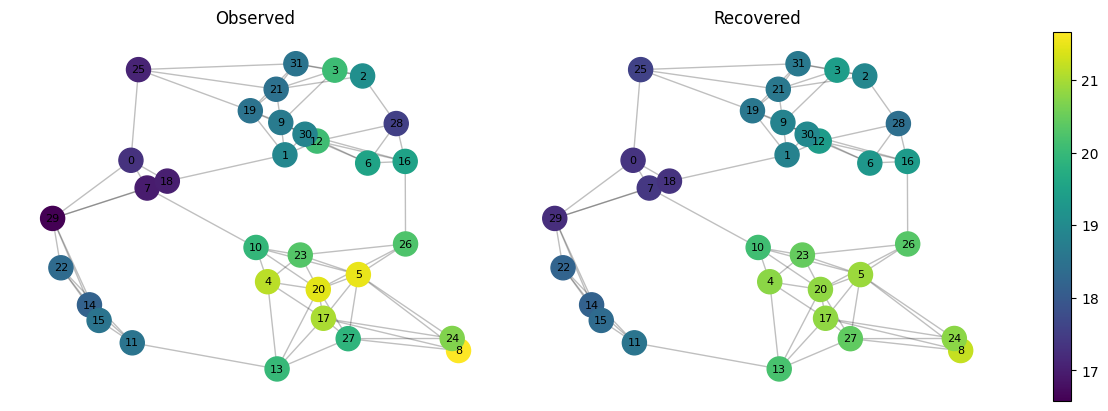

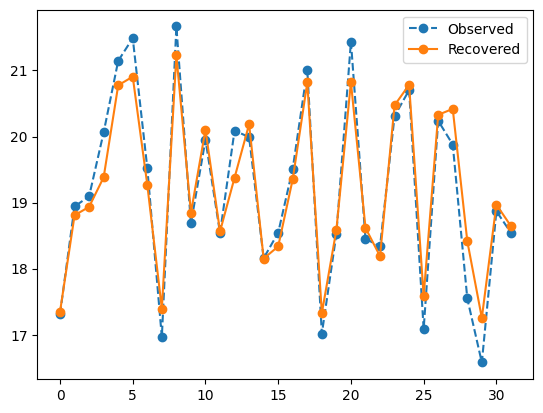

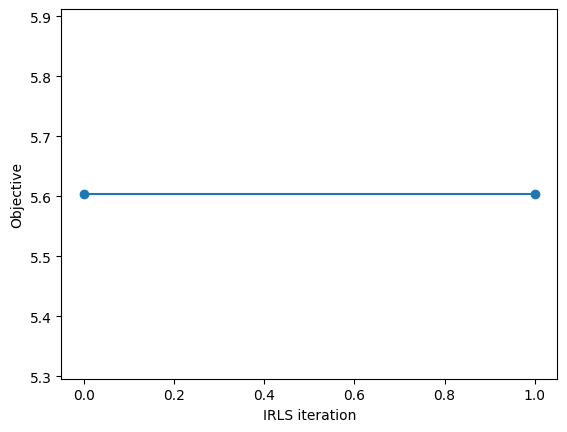

In [3]:
def scale(y,W,m):
    r=np.array([y[i]-np.median(y[(W[i]>0)&m]) for i in np.flatnonzero(m) if np.any((W[i]>0)&m)])
    return max(1e-6,1.4826*np.median(abs(r-np.median(r)))) if len(r) else 1e-6
def objective(x,y,L,lam,d,m):
    r=abs(x[m]-y[m]); loss=.5*r*r if np.isinf(d) else np.where(r<=d,.5*r*r,d*(r-.5*d))
    return loss.sum()+lam/2*x@L@x
def fit(y,L,lam,d=np.inf,m=None,trace=False):
    m=np.ones(len(y),bool) if m is None else m
    x=solve(np.diag(m.astype(float))+lam*L,m*y,assume_a='pos'); hist=[objective(x,y,L,lam,d,m)]
    for k in range(2000):
        a=m*np.minimum(1,d/np.maximum(abs(x-y),1e-15))
        z=solve(np.diag(a)+lam*L,a*y,assume_a='pos')
        hist.append(objective(z,y,L,lam,d,m)); x=z
        g=m*np.clip(x-y,-d,d)+lam*L@x
        if np.linalg.norm(g,np.inf)<1e-7: break
    else: raise RuntimeError('No convergence')
    assert max(np.diff(hist))<1e-8
    return (x,hist) if trace else x
def tune(y,W,L):
    scores=[]; folds=[]
    for i in range(len(y)):
        m=np.arange(len(y))!=i; folds.append((i,m,scale(y,W,m)))
    for lam in [.03,.1,.3,1,3,10]:
        for f in [.5,1,2,np.inf]:
            e=[fit(y,L,lam,f*s,m)[i]-y[i] for i,m,s in folds]
            scores.append((lam,f,np.mean(abs(np.array(e))),np.sqrt(np.mean(np.square(e)))))
    tab=pd.DataFrame(scores,columns=['lambda','factor','CV_MAE','CV_RMSE'])
    def pick(t):
        return t[t.CV_MAE<=t.CV_MAE.min()+1e-8].sort_values(['factor','lambda'],ascending=[False,True]).iloc[0]
    return tab,pick(tab[np.isinf(tab.factor)]),pick(tab)
def apply(y,W,L,row,trace=False):
    return fit(y,L,row['lambda'],row.factor*scale(y,W,np.ones(len(y),bool)),trace=trace)
tab,l2,best=tune(y,W,L); print(tab.to_string(index=False)); print('Chosen:',best.to_dict())
x_hat,hist=apply(y,W,L,best,True); x2=apply(y,W,L,l2)
d=best.factor*scale(y,W,np.ones(len(y),bool)); lam=best['lambda']
m=np.ones(len(y),bool); grad=lambda x: np.clip(x-y,-d,d)+lam*L@x
check=minimize(lambda x: objective(x,y,L,lam,d,m),y,jac=grad,method='BFGS',options={'gtol':1e-8})
print('Energy:',y@L@y,x_hat@L@x_hat,'gradient inf:',np.linalg.norm(grad(x_hat),np.inf),'BFGS objective gap:',abs(check.fun-hist[-1]))
print(pd.DataFrame({'node':nodes,'y':y,'x_hat':x_hat}).to_string(index=False))
graphplot(y,x_hat)
plt.plot(nodes,y,'o--',label='Observed');plt.plot(nodes,x_hat,'o-',label='Recovered');plt.legend();plt.show()
plt.plot(hist,'o-');plt.ylabel('Objective');plt.xlabel('IRLS iteration');plt.show()


## VII. Kiểm thử có ground truth mô phỏng
Dùng ba cấu trúc đồ thị thật đầu tiên theo thứ tự MSSV, không thay thế cạnh. Tạo tín hiệu sạch bằng tổ hợp 4 vector riêng phi hằng tần số thấp, chuẩn hóa trung bình 19 và độ lệch chuẩn 1. Hai mức nhiễu Gaussian (0.2 và 0.6), hai tỷ lệ ngoại lai (0 và 3/32, sai lệch ±3), mỗi cấu hình lặp 3 lần trên mỗi đồ thị. Tổng 36 test case; seed 2026. Mỗi test chọn tham số chỉ từ quan sát bằng đúng quy trình trên. So sánh không xử lý, trung bình trọng số hàng xóm, L2 và mô hình được chọn trong họ Huber (bao gồm L2). Thực nghiệm nhỏ để kiểm tra cơ chế, không phải bằng chứng tổng quát; tín hiệu phổ thấp chủ động phù hợp giả thiết Laplacian. Không dùng kết quả mô phỏng thay CSV.

                                    mean     std
sigma outliers method                           
0.2   0        Adaptive Huber/L2  0.1843  0.0239
               L2                 0.1843  0.0239
               Neighbor           0.2518  0.0648
               Raw                0.2035  0.0255
      3        Adaptive Huber/L2  0.3365  0.1752
               L2                 0.7221  0.1318
               Neighbor           0.4490  0.0662
               Raw                0.9463  0.0485
0.6   0        Adaptive Huber/L2  0.5096  0.0915
               L2                 0.5096  0.0915
               Neighbor           0.3503  0.0837
               Raw                0.5869  0.0868
      3        Adaptive Huber/L2  0.6035  0.1623
               L2                 0.8065  0.1794
               Neighbor           0.5321  0.0758
               Raw                1.1197  0.1013
Overall: {'Adaptive Huber/L2': 0.4084913759264714, 'L2': 0.5556283777257387, 'Neighbor': 0.3957768730031994, 'Raw': 0.

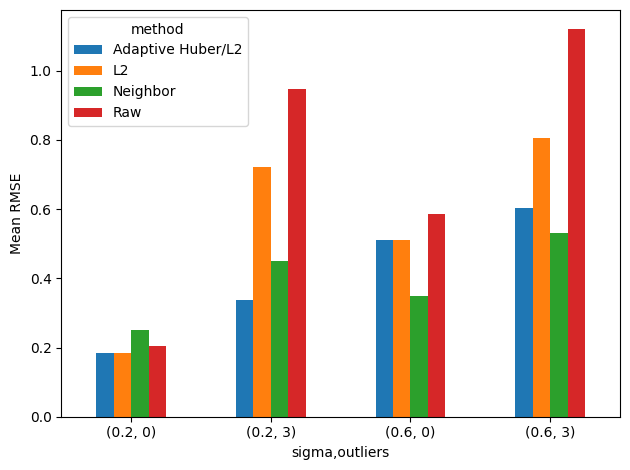

In [4]:
rng=np.random.default_rng(2026); records=[]
for k in sorted(db['cases'])[:3]:
    _,_,_,w,l,_=load_case(k); _,u=np.linalg.eigh(l)
    for sigma in [.2,.6]:
        for out in [0,3]:
            for rep in range(3):
                clean=u[:,1:5]@rng.normal(size=4); clean=19+(clean-clean.mean())/clean.std()
                obs=clean+rng.normal(0,sigma,32); idx=rng.choice(32,out,replace=False); obs[idx]+=rng.choice([-3,3],out)
                _,a,b=tune(obs,w,l)
                for name,pred in [('Raw',obs),('Neighbor',w@obs/w.sum(1)),('L2',apply(obs,w,l,a)),('Adaptive Huber/L2',apply(obs,w,l,b))]:
                    records.append((k,sigma,out,rep,name,np.sqrt(np.mean((pred-clean)**2)),np.mean(abs(pred-clean)),b.factor))
res=pd.DataFrame(records,columns=['case','sigma','outliers','rep','method','RMSE','MAE','chosen_factor'])
summary=res.groupby(['sigma','outliers','method']).RMSE.agg(['mean','std']).round(4)
print(summary.to_string()); print('Overall:',res.groupby('method').RMSE.mean().to_dict())
print('Adaptive finite Huber choices:',sum(np.isfinite(res[res.method=='Adaptive Huber/L2'].chosen_factor)))
res.to_csv('graph_simulation_tests.csv',index=False)
res.groupby(['sigma','outliers','method']).RMSE.mean().unstack().plot.bar(rot=0,ylabel='Mean RMSE');plt.tight_layout();plt.show()


## VIII. Xuất kết quả
CSV minh họa chỉ dùng để kiểm tra schema. Khi có file chính thức, đổi DEMO và điền đầy đủ thành viên rồi chạy lại tất cả cell. Không thể xác nhận RMSE thật của bộ đề công khai vì không có x_true.
## Tài liệu tham khảo
[1] Smooth Graph Signal Recovery via Efficient Laplacian Solvers, IEEE ICASSP 2017, https://doi.org/10.1109/ICASSP.2017.7953291 (điều chuẩn Tikhonov–Laplacian; paper dùng Gauss–Seidel, ở đây giải trực tiếp).
[2] P. J. Huber, Robust Estimation of a Location Parameter, Annals of Mathematical Statistics, 35(1), 73–101, 1964. https://doi.org/10.1214/aoms/1177703732 (ước lượng bền vững).
[3] P. W. Holland and R. E. Welsch, Robust Regression Using Iteratively Reweighted Least-Squares, Communications in Statistics – Theory and Methods, 6(9), 813–827, 1977. https://doi.org/10.1080/03610927708827533 (IRLS).

In [5]:
assert len(x_hat)==32 and np.isfinite(x_hat).all() and len(set(NHOM_MSSV))==len(NHOM_MSSV)
filename=('demo_' if DEMO else '')+f'submission_{sid}.csv'
with open(filename,'w',newline='',encoding='utf-8-sig') as f:
    wr=csv.writer(f);wr.writerow(['representative_mssv','group_mssvs','node_id','x_hat']);wr.writerows((sid,'|'.join(NHOM_MSSV),i,f'{v:.10f}') for i,v in zip(nodes,x_hat))
print(filename)

demo_submission_20260001.csv
